# MoMHA: configuration, schematic, results and routing

Code: `models/momha/` (module + `__init__.py` builder), configs: `models/momha/configs/*.yaml`.
Deviations from the reference: docs/deviations.md. Variants: docs/variant_registry.md.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
from backbone.config import list_variants, load_yaml, variant_path
for v in list_variants("momha"):
    print(f"--- {v}"); print(json.dumps(load_yaml(variant_path("momha", v)).get("structure_params", {})))

--- default
{"num_experts": 4, "heads_per_expert": 2, "k": 2, "gate_norm": "renorm", "switchloss": 0.01}
--- top1
{"num_experts": 4, "heads_per_expert": 4, "k": 1, "gate_norm": "raw", "switchloss": 0.01}


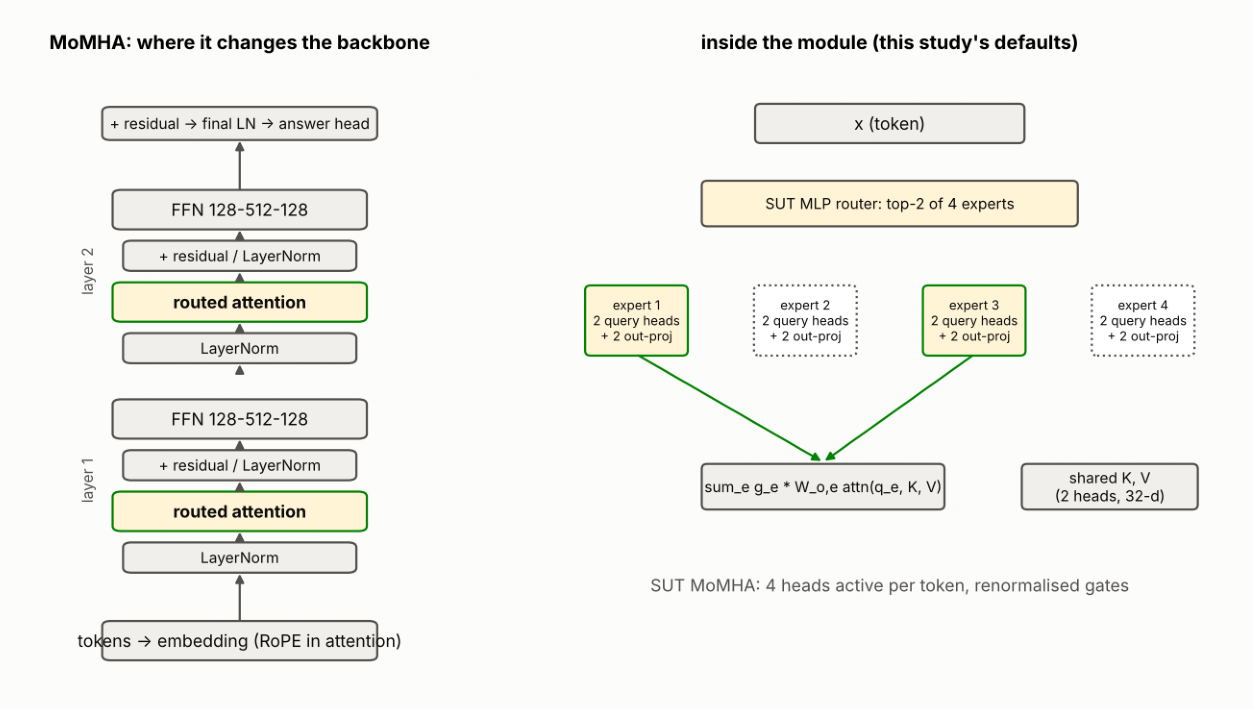

In [3]:
from analysis.schematics import draw
import matplotlib.pyplot as plt, matplotlib.image as mpimg
def show(p, size=(11, 5.5)):
    if p: plt.figure(figsize=size); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
show(draw("momha"))

In [4]:
from analysis.collect import load_results, load_routing, agg
from analysis import figures as F
df = load_results(RUNS_ROOT); d = df[df.structure == "momha"]
if len(d):
    t = agg(d, ["dataset", "variant", "balance"])
    display(t.pivot_table(index=["dataset", "variant"], columns="balance", values="mean").round(3))
else:
    print("no finished runs yet")

balance             lb   none  warmup
dataset variant                      
copy    default    NaN  1.000     NaN
fact    default  0.338  0.453   0.420
        top1     0.124  0.053   0.139
logic   default    NaN  0.571     NaN
mix     default    NaN  0.638     NaN
mod     default  0.242  0.241   0.111
mqar    default    NaN  0.123     NaN
rev     default    NaN  1.000     NaN

entropy  max_load  dead
dataset variant balance                         
copy    default none       0.900     0.417   0.0
fact    default lb         0.994     0.287   0.0
                none       0.911     0.400   0.0
                warmup     0.891     0.373   0.0
        top1    lb         0.964     0.358   0.0
                none       0.834     0.504   0.0
                warmup     0.810     0.508   0.0
logic   default none       0.801     0.446   0.0
mix     default none       0.971     0.331   0.0
mod     default lb         0.983     0.303   0.0
                none       0.827     0.448   0.0
                warmup     0.756     0.467   0.0
mqar    default none       0.821     0.445   0.0
rev     default none       0.869     0.385   0.0

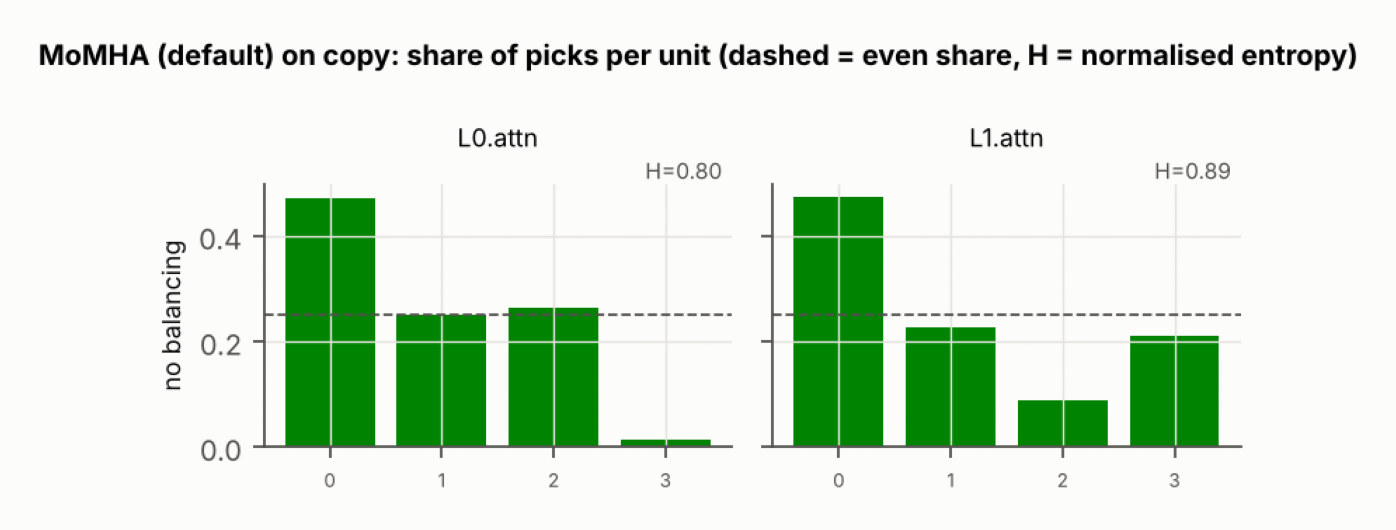

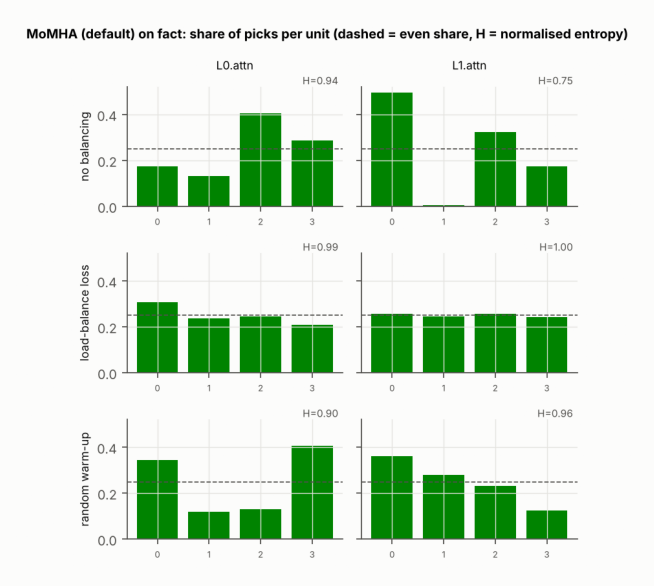

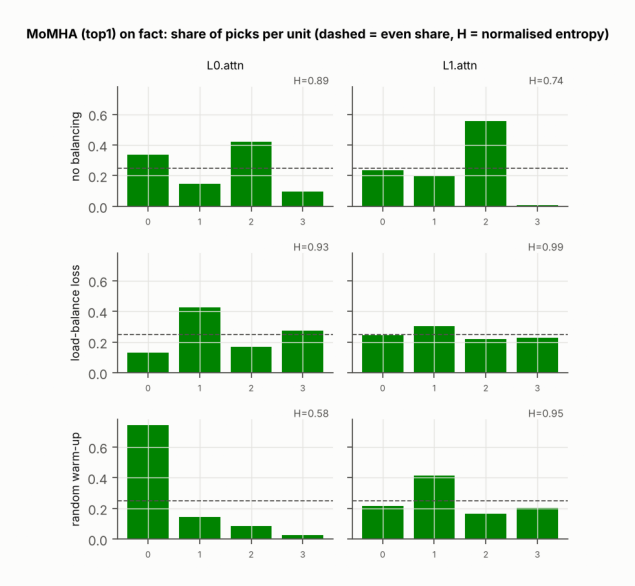

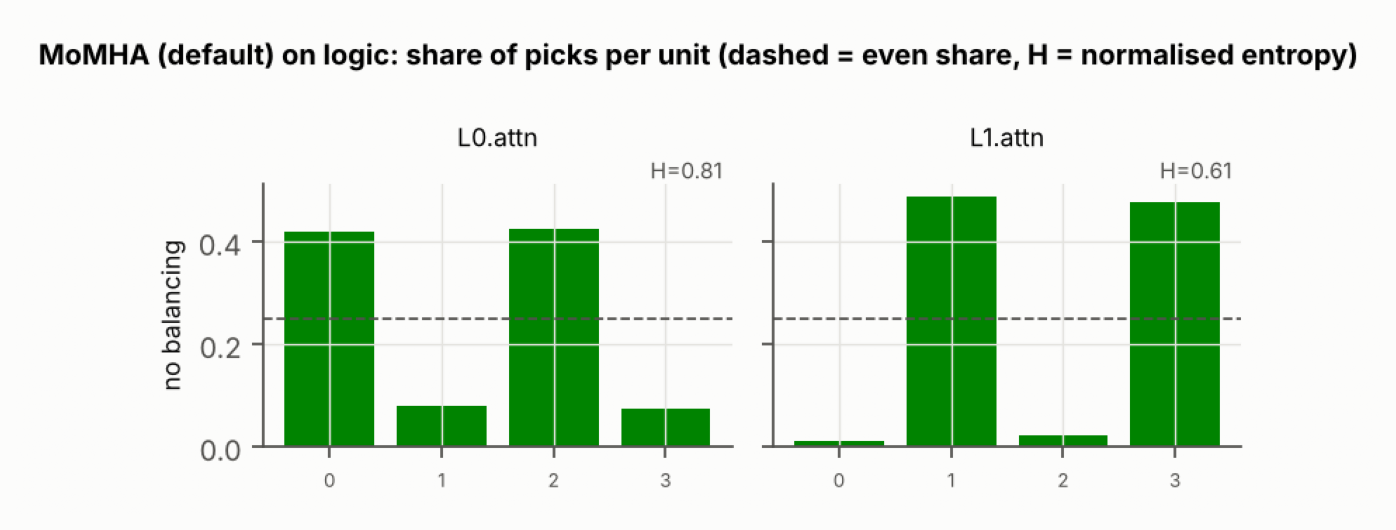

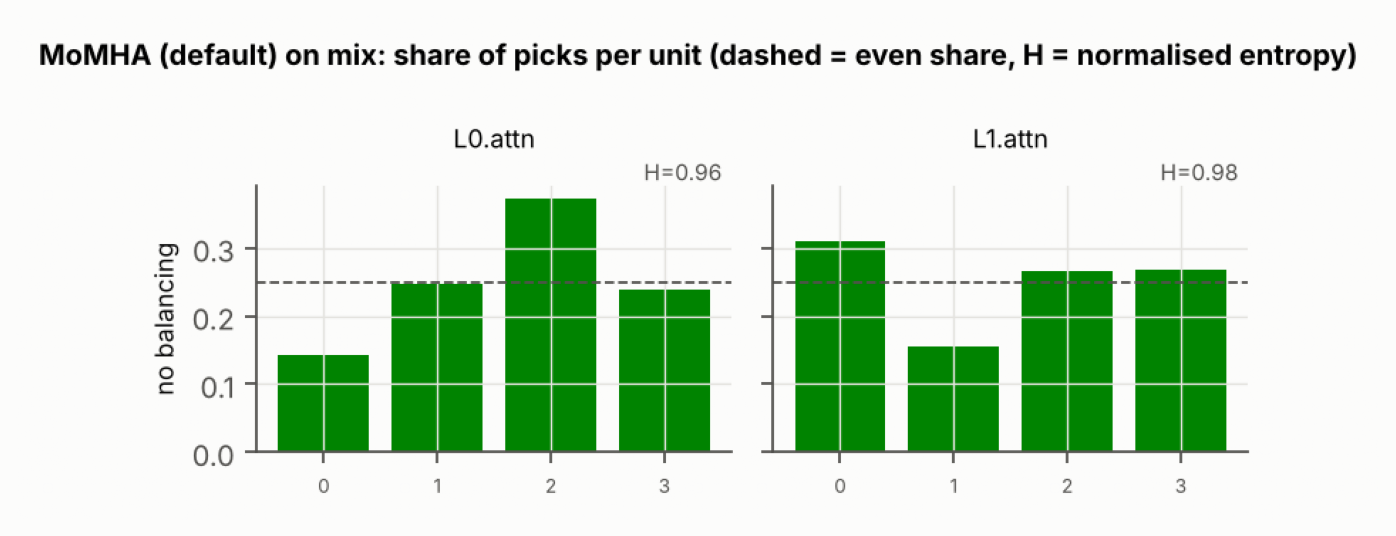

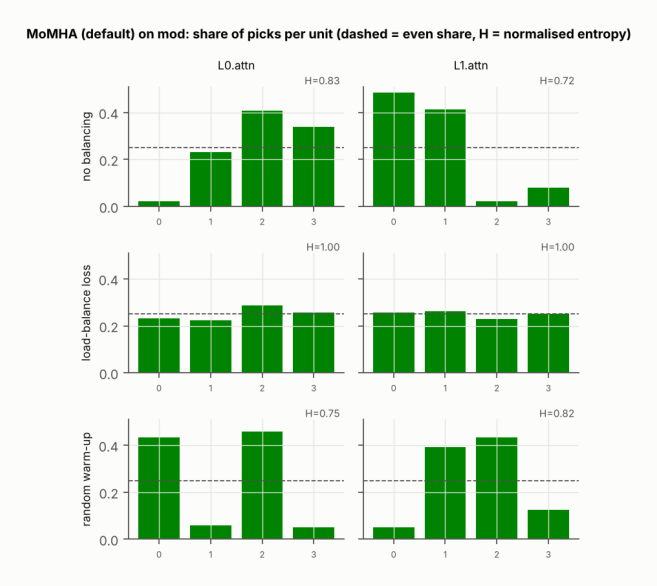

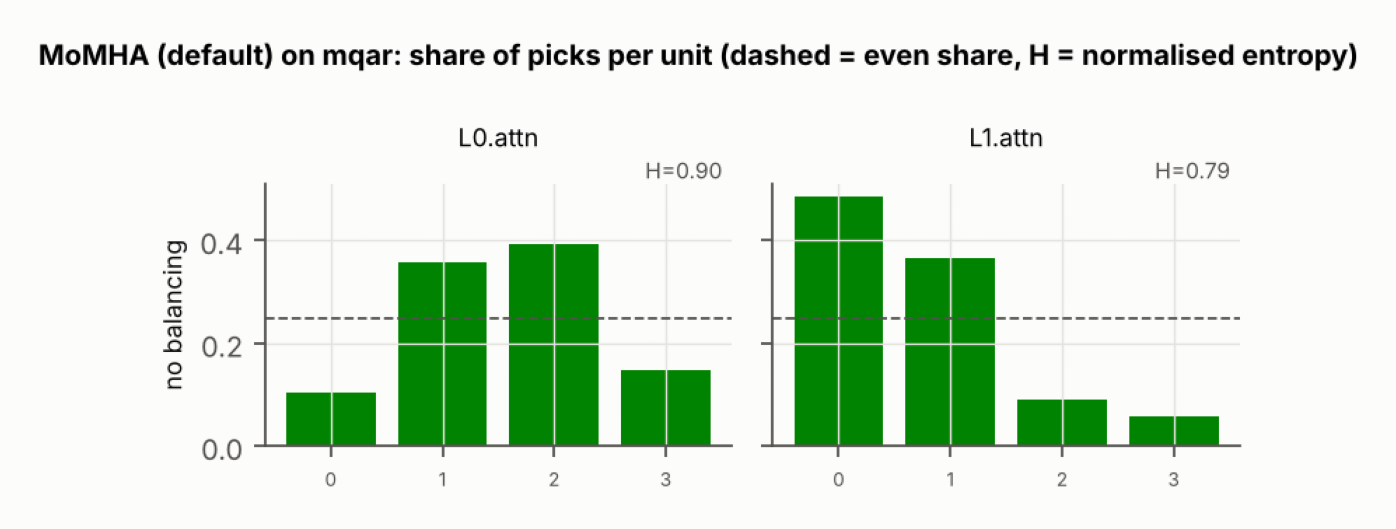

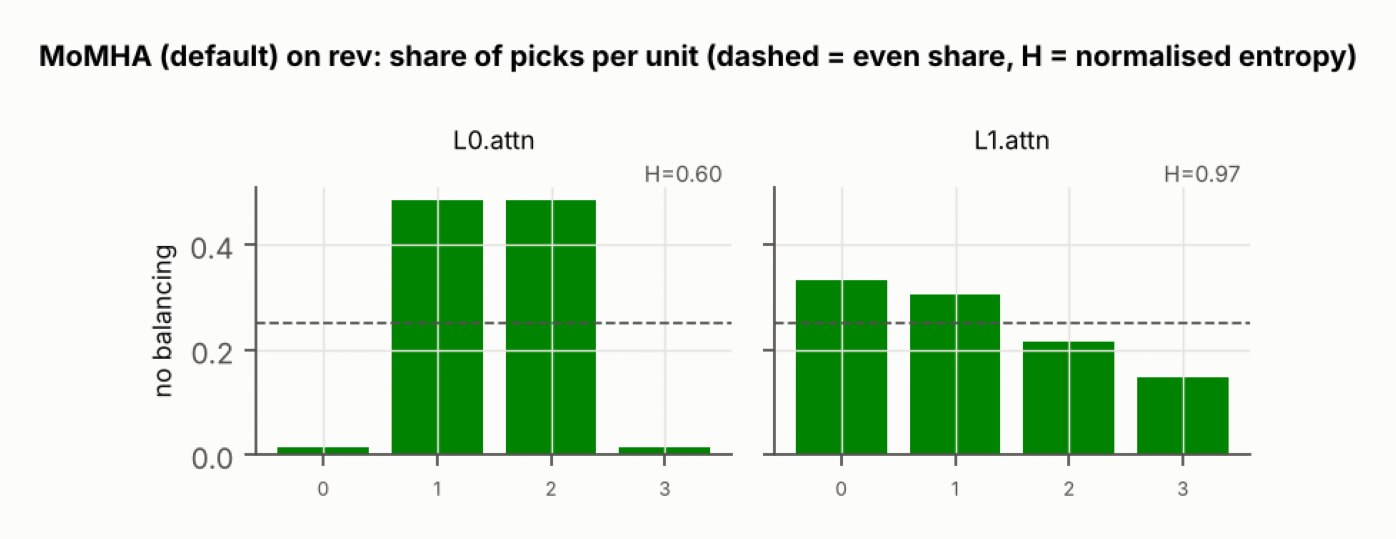

In [5]:
rdf = load_routing(RUNS_ROOT)
if len(rdf) and "momha" in set(rdf.structure):
    r = rdf[rdf.structure == "momha"]
    display(r.groupby(["dataset", "variant", "balance"])[["entropy", "max_load", "dead"]].mean().round(3))
    for ds in sorted(set(r.dataset)):
        for v in sorted(set(r[r.dataset == ds].variant)):
            show(F.routing_load(rdf, ds, "momha", v), (11, 4.5))